In [40]:
import pandas as pd

df = pd.read_csv("../out.csv")

df

,DataHora,Municipio,Bioma,DiaSemChuva,Precipitacao,RiscoFogo,Fogo
0,2024-06,ADAMANTINA,1.7,5.000000,0.0,0.603188,0
1,2024-07,ADAMANTINA,1.7,74.201035,0.0,1.000000,1
2,2024-08,ADAMANTINA,1.7,104.335641,0.0,1.000000,1
3,2024-09,ADAMANTINA,1.7,7.000000,0.0,0.876260,0
4,2024-10,ADAMANTINA,1.7,103.101834,0.0,1.000000,1
...,...,...,...,...,...,...,...
8132,2025-02,ÓLEO,1.7,0.000000,10.3,0.003169,0
8133,2025-03,ÓLEO,1.7,96.342288,0.0,0.130000,1
8134,2025-04,ÓLEO,1.7,0.000000,2.4,0.508753,0
8135,2025-05,ÓLEO,1.7,2.000000,0.0,0.484435,0


In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[["Bioma", "DiaSemChuva", "Precipitacao", "RiscoFogo"]]
y = df["Fogo"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [42]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(8),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

mlp.fit(X_train_scaled, y_train)

y_pred = mlp.predict(X_test_scaled)
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 0.8894

Matriz de Confusão:
[[745  51]
 [129 703]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.85      0.94      0.89       796
           1       0.93      0.84      0.89       832

    accuracy                           0.89      1628
   macro avg       0.89      0.89      0.89      1628
weighted avg       0.89      0.89      0.89      1628



In [43]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Nota: Modelos baseados em árvores não exigem dados escalonados (X_train_scaled),
# mas funcionam perfeitamente com eles se você quiser manter o padrão do pipeline.
gb.fit(X_train_scaled, y_train)

y_pred = gb.predict(X_test_scaled)
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 0.8980

Matriz de Confusão:
[[736  60]
 [106 726]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.87      0.92      0.90       796
           1       0.92      0.87      0.90       832

    accuracy                           0.90      1628
   macro avg       0.90      0.90      0.90      1628
weighted avg       0.90      0.90      0.90      1628



In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

lr = LogisticRegression(
    random_state=42,
    n_jobs=-1,
    max_iter=1000
)

lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 0.7506

Matriz de Confusão:
[[553 243]
 [163 669]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.77      0.69      0.73       796
           1       0.73      0.80      0.77       832

    accuracy                           0.75      1628
   macro avg       0.75      0.75      0.75      1628
weighted avg       0.75      0.75      0.75      1628



/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [45]:
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.model_selection import train_test_split
from sklearn.gaussian_process import GaussianProcessClassifier

kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(
    length_scale=[1.0] * X_train_scaled.shape[1], 
    length_scale_bounds=(1e-2, 1e2)
)

gpc = GaussianProcessClassifier(
    kernel=kernel,
    random_state=42,
    n_jobs=-1
)

gpc.fit(X_train_scaled, y_train)

y_pred = gpc.predict(X_test_scaled)
y_prob = gpc.predict_proba(X_test_scaled)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 0.9318

Matriz de Confusão:
[[763  33]
 [ 78 754]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.91      0.96      0.93       796
           1       0.96      0.91      0.93       832

    accuracy                           0.93      1628
   macro avg       0.93      0.93      0.93      1628
weighted avg       0.93      0.93      0.93      1628



In [46]:
teste = pd.DataFrame([
    {
        "Bioma": 1.7,
        "DiaSemChuva": 20,
        "Precipitacao": 0,
        "RiscoFogo": 1,
    }
])

teste_s = scaler.transform(teste)

print(f'Probabilidade de incêndio (MLP): {mlp.predict_proba(teste_s)[0][1]:.2f}')
print(f'Probabilidade de incêndio (GPC): {gpc.predict_proba(teste_s)[0][1]:.2f}')
print(f'Probabilidade de incêndio (LR): {lr.predict_proba(teste_s)[0][1]:.2f}')

Probabilidade de incêndio (MLP): 0.58
Probabilidade de incêndio (GPC): 0.91
Probabilidade de incêndio (LR): 0.42


/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/erick/Documentos/queimadas/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not ha

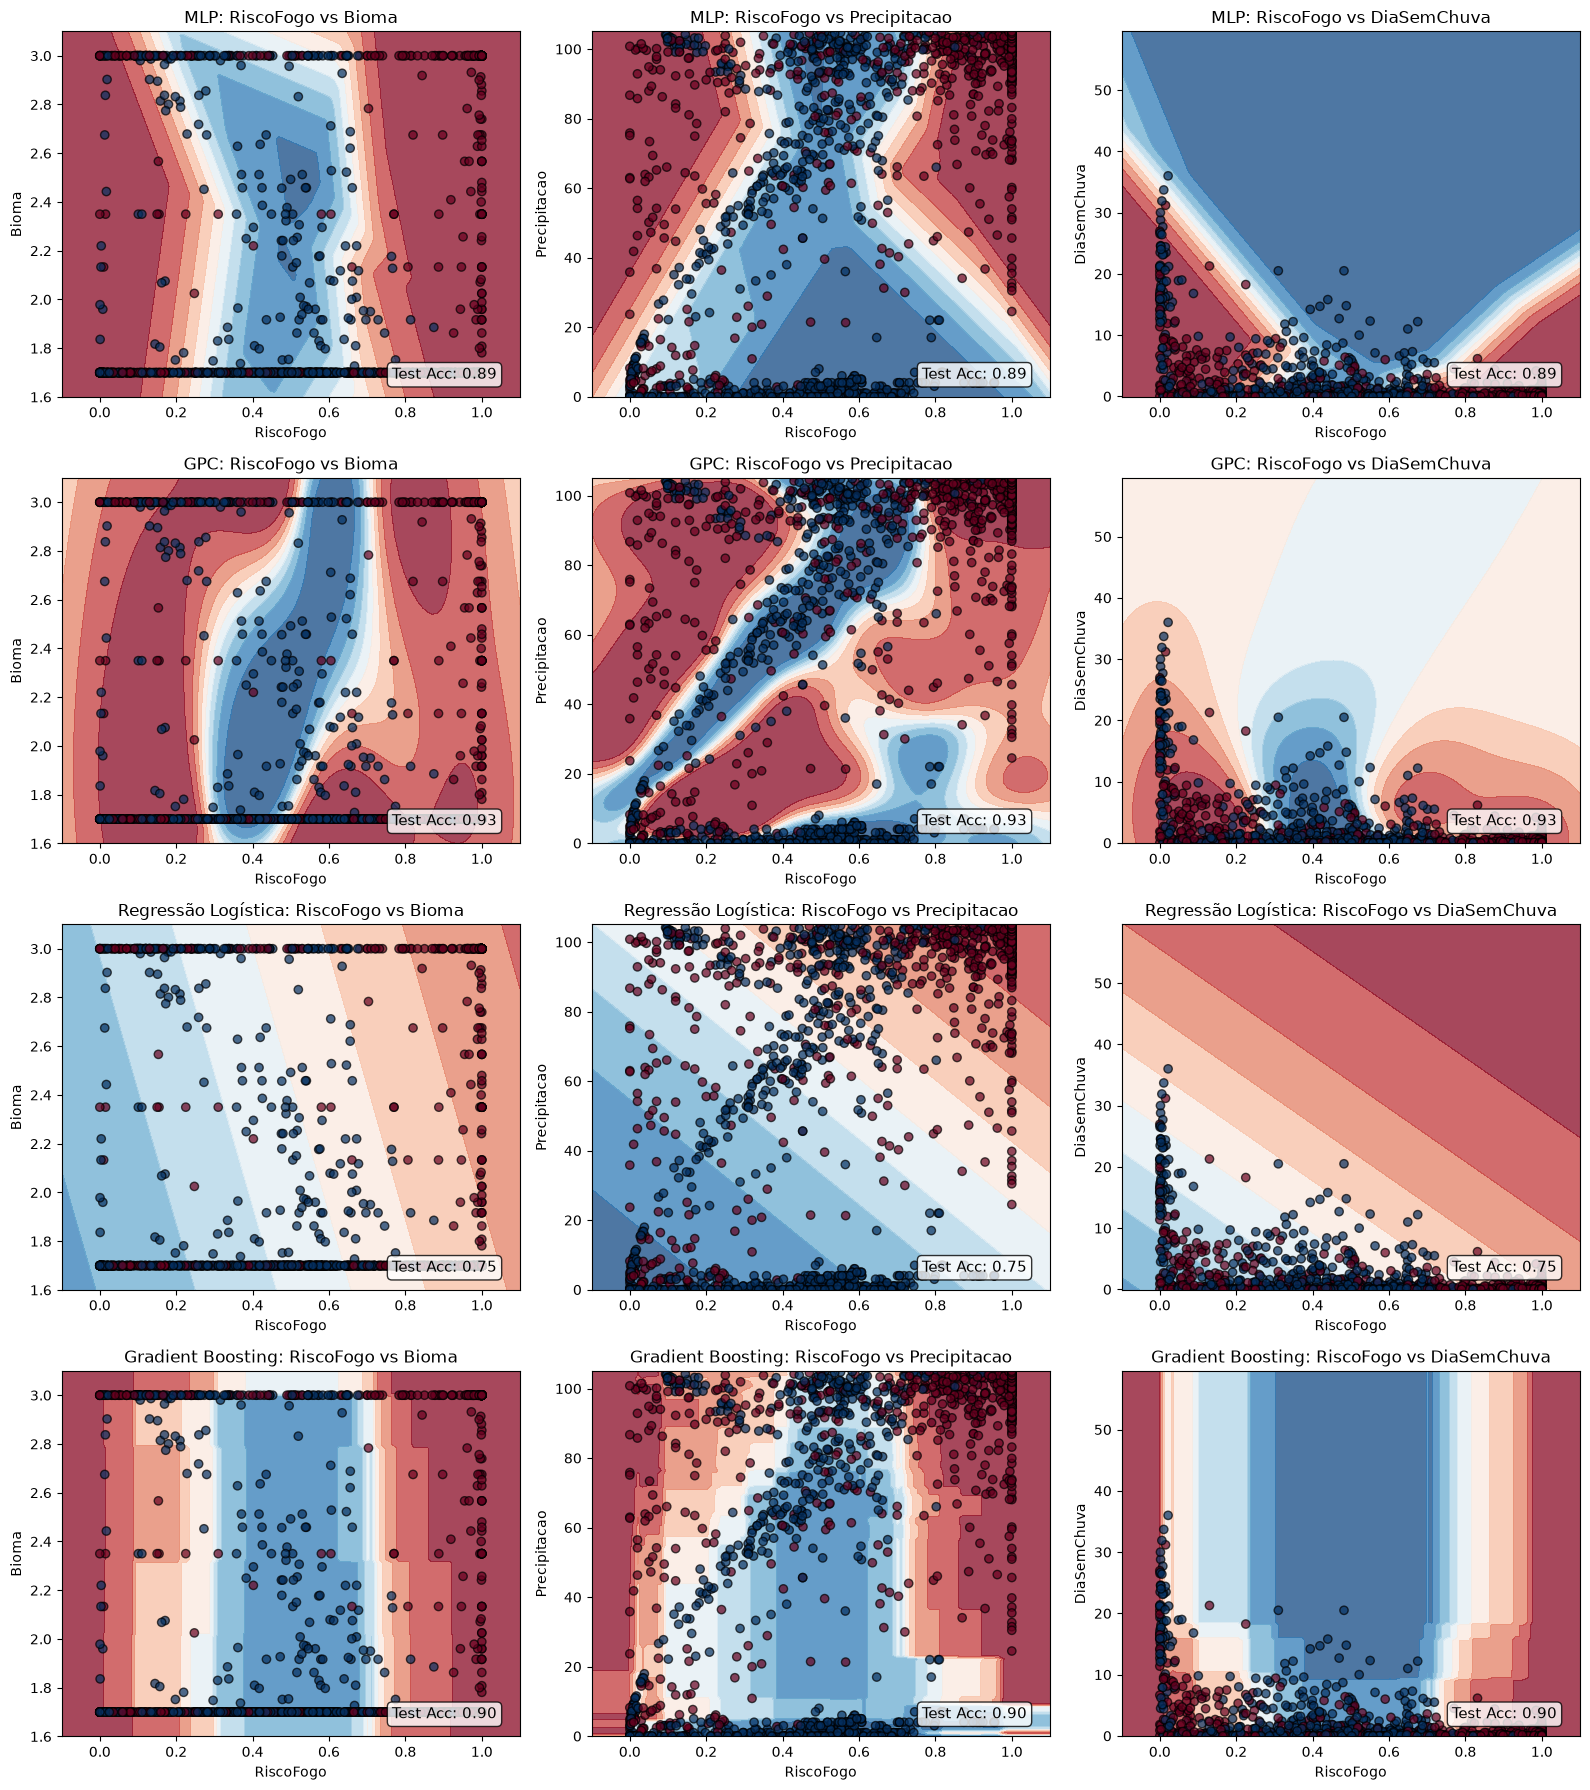

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# Garante a conversão para array NumPy se forem DataFrames do Pandas
X_tr = X_train.to_numpy() if hasattr(X_train, "to_numpy") else X_train
X_te = X_test.to_numpy() if hasattr(X_test, "to_numpy") else X_test
y_tr = y_train.to_numpy() if hasattr(y_train, "to_numpy") else y_train
y_te = y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test

# Setup atualizado para as 4 colunas de X (incluindo DiaSemChuva)
features = ["Bioma", "Precipitacao", "DiaSemChuva", "RiscoFogo"]
rf_idx = 3  # Índice atualizado do RiscoFogo
other_indices = [0, 1, 2]  # Bioma (0), Precipitacao (1) e DiaSemChuva (2)

mean_unscaled = X_tr.mean(axis=0)

# 4 linhas (modelos) e 3 colunas (features comparadas com RiscoFogo)
fig, axes = plt.subplots(4, 3, figsize=(16, 18))

models_info = [
    ("MLP", mlp, axes[0]),
    ("GPC", gpc, axes[1]),
    ("Regressão Logística", lr, axes[2]),
    ("Gradient Boosting", gb, axes[3]),
]

for model_name, model, row_axes in models_info:
    # Calcula a acurácia uma única vez por modelo (otimização)
    acc = model.score(X_test_scaled, y_te)
    
    for i, other_idx in enumerate(other_indices):
        ax = row_axes[i]

        # Limites na escala original das features
        x_min, x_max = X_tr[:, rf_idx].min() - 0.1, X_tr[:, rf_idx].max() + 0.1
        y_min, y_max = (
            X_tr[:, other_idx].min() - 0.1,
            X_tr[:, other_idx].max() + 0.1,
        )

        xx, yy = np.meshgrid(
            np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100)
        )

        # Matriz para predizer probabilidade (mantém as demais features na média)
        grid_unscaled = np.tile(mean_unscaled, (xx.ravel().shape[0], 1))
        grid_unscaled[:, rf_idx] = xx.ravel()
        grid_unscaled[:, other_idx] = yy.ravel()
        grid_scaled = scaler.transform(grid_unscaled)

        Z = model.predict_proba(grid_scaled)[:, 1].reshape(xx.shape)

        # Plot com cmap=plt.cm.RdBu_r (Vermelho = Fogo / Azul = Não-Fogo)
        ax.contourf(
            xx,
            yy,
            Z,
            levels=np.linspace(0, 1, 11),
            cmap=plt.cm.RdBu_r,
            vmin=0,
            vmax=1,
            alpha=0.75,
        )
        ax.scatter(
            X_te[:, rf_idx],
            X_te[:, other_idx],
            c=y_te,
            cmap=plt.cm.RdBu_r,
            vmin=0,
            vmax=1,
            edgecolors="k",
            alpha=0.7,
        )

        ax.set_xlabel("RiscoFogo")
        ax.set_ylabel(features[other_idx])
        ax.set_title(f"{model_name}: RiscoFogo vs {features[other_idx]}")

        ax.text(
            0.95,
            0.05,
            f"Test Acc: {acc:.2f}",
            transform=ax.transAxes,
            size=11,
            horizontalalignment="right",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        )

plt.tight_layout()
plt.show()

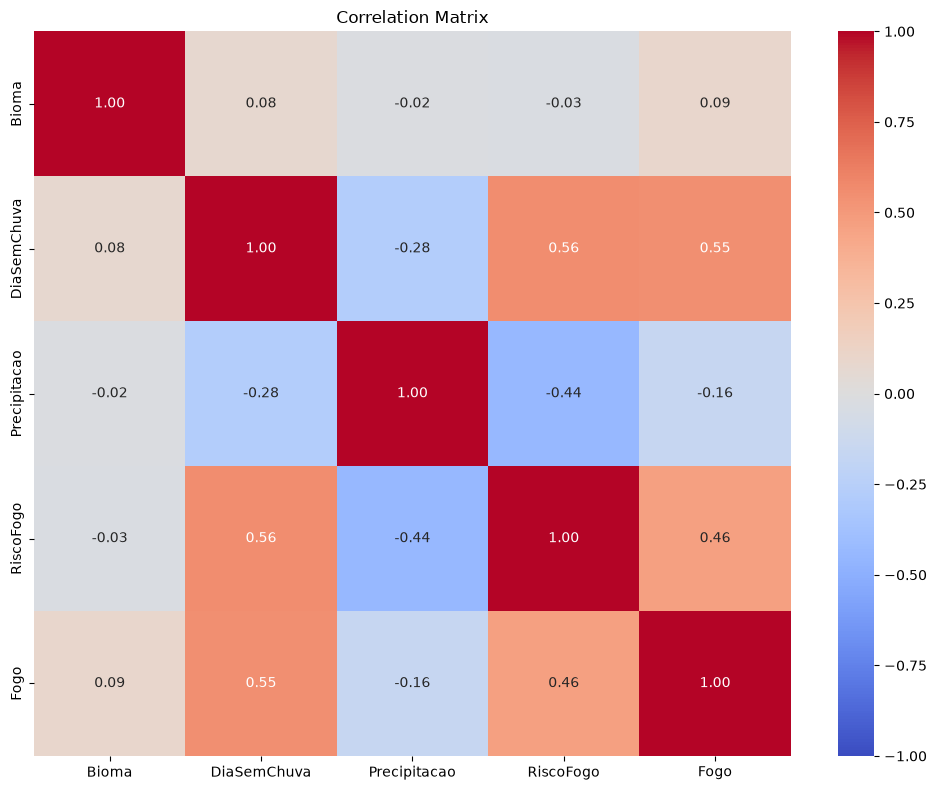

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

# df is your pandas DataFrame
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


In [52]:
import pickle

pickle.dump(gpc, open(f'../out/gpc-2026.pkl', 'wb'))
pickle.dump(mlp, open(f'../out/mlp-2026.pkl', 'wb'))
pickle.dump(gb, open(f'../out/gb-2026.pkl', 'wb'))
pickle.dump(lr, open(f'../out/lr-2026.pkl', 'wb'))
pickle.dump(scaler, open(f'../out/scaler-2026.pkl', 'wb'))
